# ШАГ 1: Формулировка гипотез

Цель исследования - поиск факторов влияющий на успех игр и поиск скрытых зависимостей.
Сформулируем гипотезы:
1. Жанры «Action», «RPG», «Indie» доминируют по количеству игроков.
2. Высокая скидка (%) не всегда коррелирует с ростом оценок.
3. Дешевизна инди проектов один из факторов продаж/высоких оценок
4. ААА проекты покупают несмотря на цену
5. Чем выше цена, тем выше ожидания → оценки могут быть ниже.
5. Игры с мультиплеером имеют более высокий 24h_Peak_Players.
6. Бесплатные игры имеют низкие оценки, но огромную аудиторию.
Для каждой гипотезы указать статистический тест и порог значимости (p < 0.05)

# ШАГ 2: Загрузка и предобработка данных

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from pathlib import Path
import pingouin as pg
import scikit_posthocs as sp
import os


from IPython.core.pylabtools import figsize
from matplotlib.pyplot import title
from pandas import pivot_table

project_root = Path.cwd().parent
file_path = project_root / 'data' / 'steam_games_2026.csv'
df = pd.read_csv(file_path)
df.columns = df.columns.str.lower()
df.head()

,appid,name,release_date,primary_genre,all_tags,price_usd,discount_pct,review_score_pct,total_reviews,steam_deck_status,estimated_owners,24h_peak_players
0,730,Counter-Strike 2,2012-08-21,Action,FPS;Shooter;Multiplayer;Competitive;Action;Tea...,0.00,0,83,4980365,Unknown,149410950,1013936
1,2868840,Slay the Spire 2,2026-03-05,Indie,Strategy;Roguelike;Card Game;Deckbuilding;Co-o...,24.99,0,97,49549,Unknown,1486470,0
2,3321460,Crimson Desert,2026-03-19,Action,Action;Open World;Singleplayer;Adventure;Comba...,69.99,0,0,0,Unknown,0,0
3,3065800,Marathon,2026-03-05,Action,Extraction Shooter;PvP;Multiplayer;Sci-fi;Shoo...,39.99,0,90,24360,Unknown,730800,0
4,3764200,Resident Evil Requiem,2026-02-26,Action,Survival Horror;Zombies;Horror;Third-Person Sh...,69.99,0,96,79667,Unknown,2390010,0


In [2]:
condition = (
        ((df['estimated_owners'].isna()) | (df['estimated_owners'] == 0)) &
        ((df['total_reviews'].isna()) | (df['total_reviews'] == 0)) &
        ((df['24h_peak_players'].isna())| (df['24h_peak_players'] == 0)))
df = df.loc[~condition]

df['price_usd'] = df['price_usd'].fillna(0)
df['discount_pct'] = df['discount_pct'].fillna(0)
df['24h_peak_players'] = df['24h_peak_players'].fillna(0)
df = df[df['review_score_pct'] != 0]
df.drop(columns=['steam_deck_status'], inplace=True)
df['release_date'] = pd.to_datetime(df['release_date'])

df['is_free'] = df['price_usd'] == 0
df['release_year'] = df['release_date'].dt.year.astype('Int64').fillna(0)
df.head()

,appid,name,release_date,primary_genre,all_tags,price_usd,discount_pct,review_score_pct,total_reviews,estimated_owners,24h_peak_players,is_free,release_year
0,730,Counter-Strike 2,2012-08-21,Action,FPS;Shooter;Multiplayer;Competitive;Action;Tea...,0.00,0,83,4980365,149410950,1013936,True,2012
1,2868840,Slay the Spire 2,2026-03-05,Indie,Strategy;Roguelike;Card Game;Deckbuilding;Co-o...,24.99,0,97,49549,1486470,0,False,2026
3,3065800,Marathon,2026-03-05,Action,Extraction Shooter;PvP;Multiplayer;Sci-fi;Shoo...,39.99,0,90,24360,730800,0,False,2026
4,3764200,Resident Evil Requiem,2026-02-26,Action,Survival Horror;Zombies;Horror;Third-Person Sh...,69.99,0,96,79667,2390010,0,False,2026
5,2157830,John Carpenter's Toxic Commando,2026-03-12,Action,Zombies;Shooter;Online Co-Op;FPS;PvE;Action;Ad...,39.99,0,83,2765,82950,0,False,2026


На этом этапе провели очистку данных:
1. Удалили не вышедшие игры: владельцы, ревью и пиковый онлайн отсутствует значение или равны нулю. Если бы игра была релизнута, то хотя бы одно из полей было больше нуля.
2. Заполнили пустые значения в полях цена, скидка и пиковый онлайн нулями.
3. Удалили игры с 0% положительных ревью. Для текущего анализа они не нужны, а также могут являться ошибками сбора данных.
4. Удалили поле со статусом стим дека: все игры имеют по нему статус 0.
5. Преобразовали поле даты релиза к типу date_time
6. Создали новые признаки: тег бесплатной игры, год релиза без даты и месяца

# ШАГ 3: Исследовательский анализ

### Проверка на нормальность
#### Графический метод: Q-Q plot

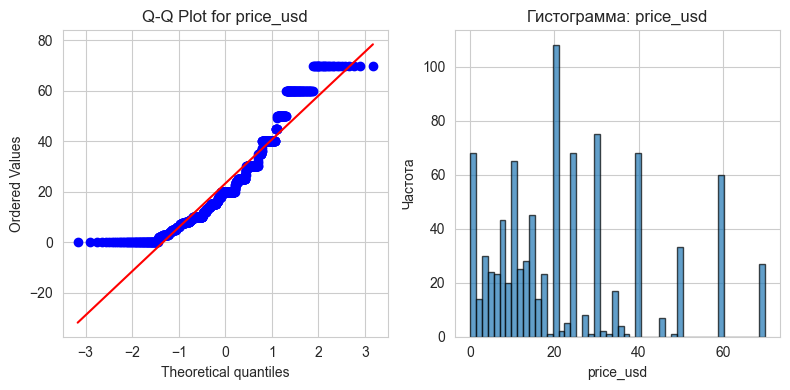

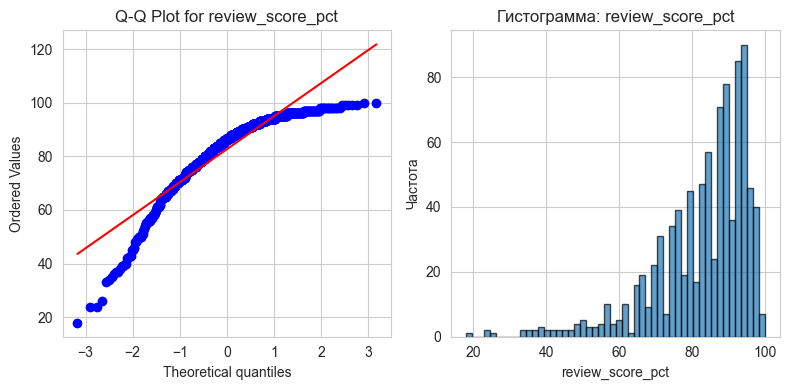

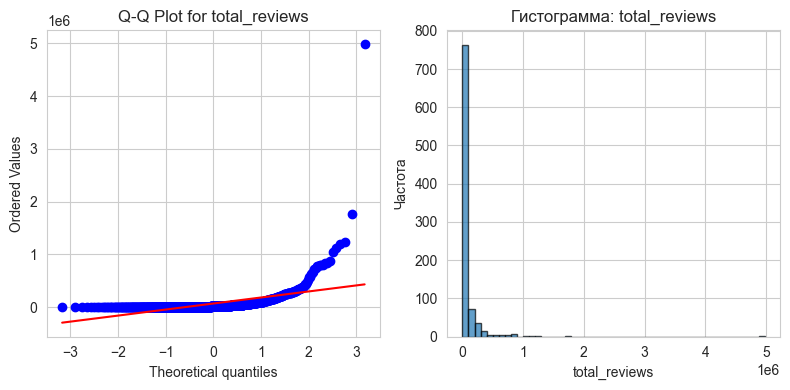

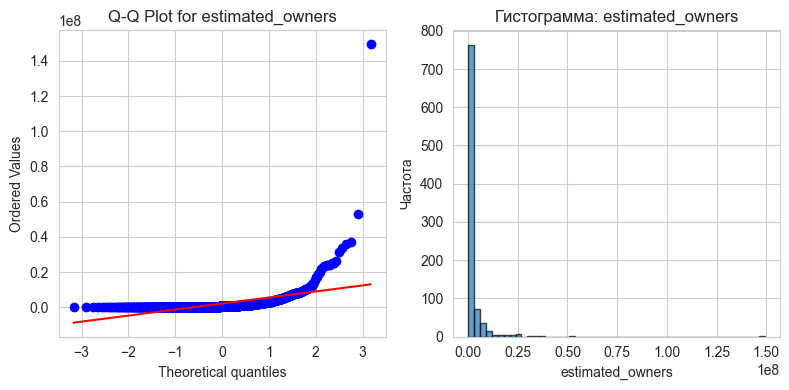

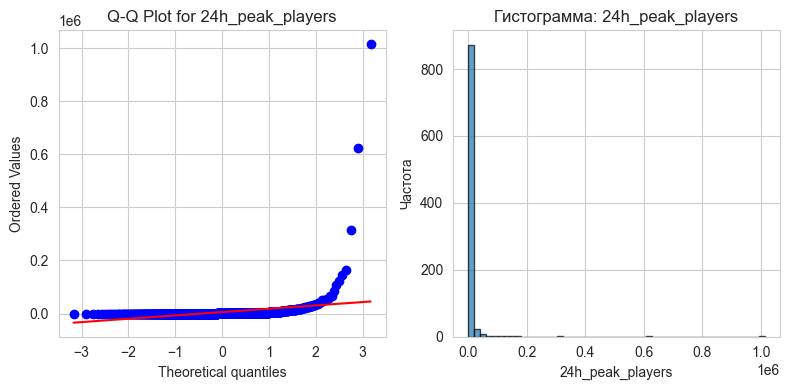

In [3]:
project_root = Path.cwd().parent
output_dir = project_root / 'outputs'/ 'visualization'
os.makedirs(output_dir, exist_ok=True)
sns.set_style("whitegrid")
numeric_features = [ 'price_usd', 'review_score_pct', 'total_reviews', 'estimated_owners', '24h_peak_players']
for col in numeric_features:
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    stats.probplot(df[col], dist='norm', plot = axes[0])
    axes[0].set_title('Q-Q Plot for ' + col)
    axes[1].hist(df[col], bins=50, edgecolor='black', alpha=0.7)
    axes[1].set_title(f'Гистограмма: {col}')
    axes[1].set_xlabel(col)
    axes[1].set_ylabel('Частота')
    plt.tight_layout()
    file_path = os.path.join(output_dir, f'QQ_plot_{col}.png')
    plt.savefig(file_path)
    plt.show()

Очевидно данные не распределены нормально

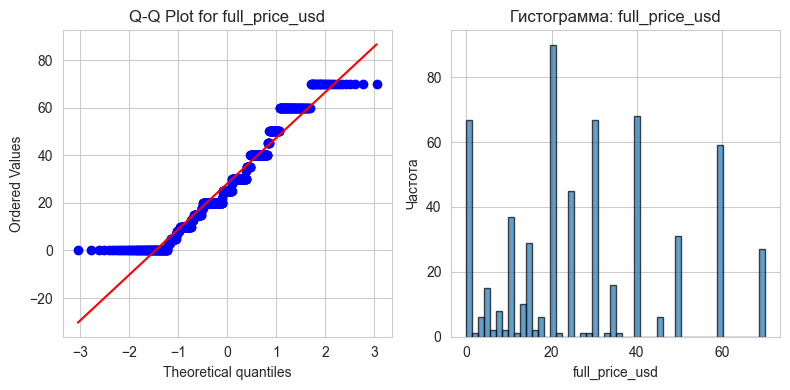

In [4]:
df['full_price_usd'] = df['price_usd'] / (1 - df['discount_pct'] / 100)
data_price = 'full_price_usd'
df_sub = df[df['discount_pct'] == 0]
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
stats.probplot(df_sub[data_price], dist='norm', plot = axes[0])
axes[0].set_title('Q-Q Plot for ' + data_price)

axes[1].hist(df_sub[data_price], bins=50, edgecolor='black', alpha=0.7)
axes[1].set_title(f'Гистограмма: {data_price}')
axes[1].set_xlabel(data_price)
axes[1].set_ylabel('Частота')
plt.tight_layout()
file_path = os.path.join(output_dir, f'QQ_plot_fprice.png')
plt.savefig(file_path)
plt.show()

Скидки временные, популярность игр же набирается годами. Поэтому создана отдельная колонка `full_price_usd` с восстановленной стоимостью.

#### Тест Шапиро-Уилка

In [5]:
for col in numeric_features:
    statistic, p_value  = stats.shapiro(df[col])
    print(f'\n  Shapiro-Wilk for {col}:  stat={statistic:.4f}, p={p_value:.2e}  → {"НЕ нормальное" if p_value < 0.05 else "нормальное (редкость!)"}')


  Shapiro-Wilk for price_usd:  stat=0.9106, p=1.03e-22  → НЕ нормальное

  Shapiro-Wilk for review_score_pct:  stat=0.8709, p=9.27e-27  → НЕ нормальное

  Shapiro-Wilk for total_reviews:  stat=0.2732, p=1.47e-50  → НЕ нормальное

  Shapiro-Wilk for estimated_owners:  stat=0.2732, p=1.47e-50  → НЕ нормальное

  Shapiro-Wilk for 24h_peak_players:  stat=0.0922, p=3.44e-54  → НЕ нормальное


#### Тест Колмогорова-Смирнова  с поправкой Лиллиефорса для ключевых метрик

In [6]:
from statsmodels.stats.diagnostic import lilliefors
for col in numeric_features:
    statistic,p_value  = lilliefors(df[col], 'norm')
    print(f'\n  K-S test: for {col}:  stat={statistic:.4f}, p={p_value:.4f}  → {"НЕ нормальное" if p_value < 0.05 else "нормальное (редкость!)"}')


  K-S test: for price_usd:  stat=0.1504, p=0.0010  → НЕ нормальное

  K-S test: for review_score_pct:  stat=0.1274, p=0.0010  → НЕ нормальное

  K-S test: for total_reviews:  stat=0.3757, p=0.0010  → НЕ нормальное

  K-S test: for estimated_owners:  stat=0.3757, p=0.0010  → НЕ нормальное

  K-S test: for 24h_peak_players:  stat=0.4467, p=0.0010  → НЕ нормальное


Ожидаемо распределение не нормальное

### Распределения
- Гистограммы `Price_USD`, `Review_Score_Pct`, `Total_Reviews`, `Estimated_Owners` (log scale)
- Количество игр по жанрам (`Primary_Genre`)
- Топ-10 самых популярных `All_Tags` (через разбивку по `;`)

Построим гистограмму распределения числовых столбцов

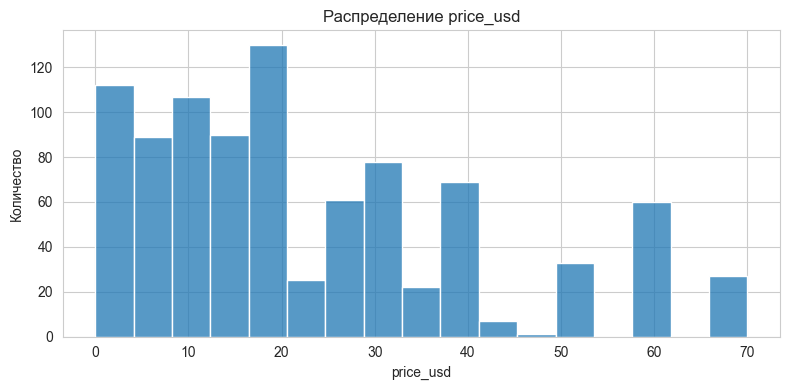

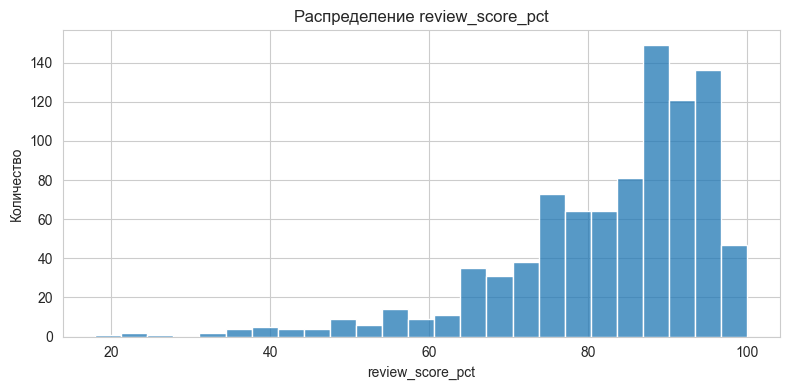

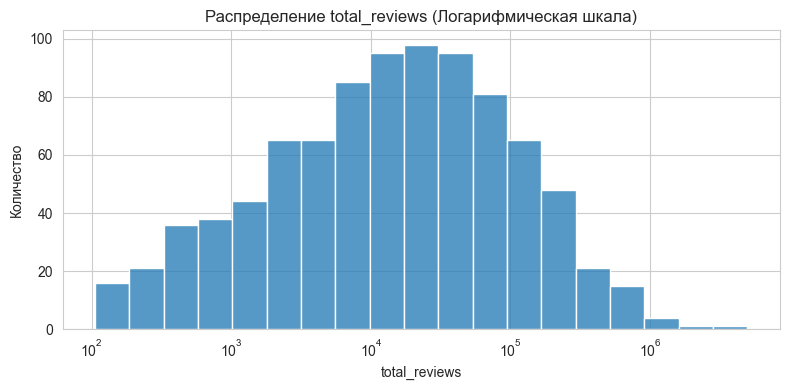

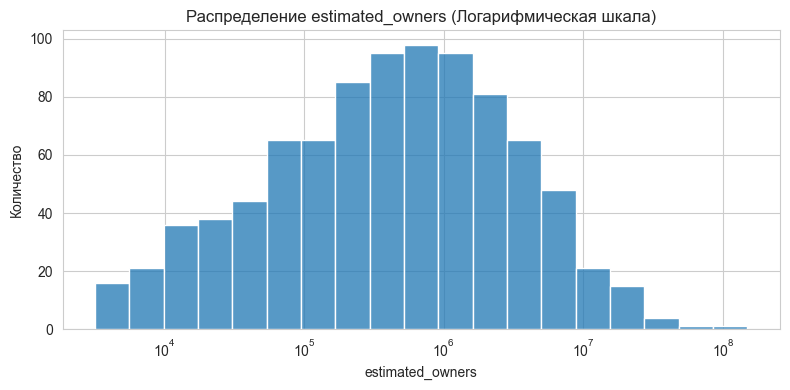

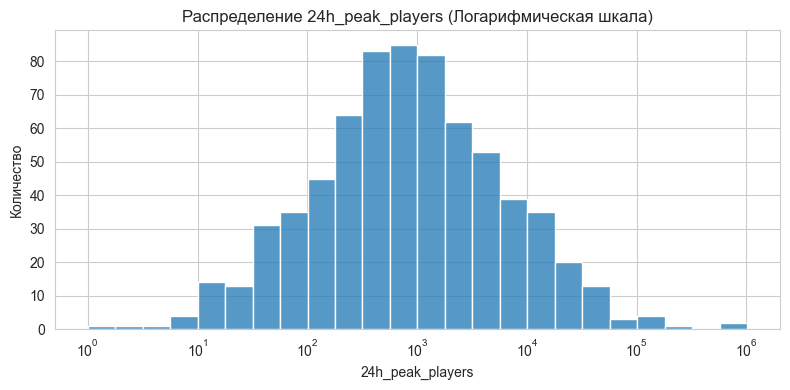

In [7]:
log_hist = [ 'total_reviews', 'estimated_owners', '24h_peak_players']
for col in numeric_features:
    fig, axes = plt.subplots(figsize=(8, 4))
    axes.set_axisbelow(True)
    if col in log_hist:
        sns.histplot(data = df, x = df[col], multiple = 'stack', log_scale=True, ax = axes, zorder=3)
        plt.title(f'Распределение {col} (Логарифмическая шкала)')
    else:
        sns.histplot(data = df, x = df[col], multiple = 'stack', ax = axes, zorder=3)
        plt.title(f'Распределение {col}')
    plt.xlabel(col)
    plt.ylabel('Количество')
    plt.tight_layout()
    file_path = os.path.join(output_dir, f'Hist_plot_{col}.png')
    plt.savefig(file_path)
    plt.show()

После логарифмического преобразования распределение `total_reviews`, `estimated_owners`, `24h_peak_players` кажется нормальным, но это не так. Это эффект логарифмической шкалы. Исходные данные имеют сильную асимметрию и логнормальное распределение, что подтверждается статистическими тестами.

Построим гистограмму распределения `primary_genre	`

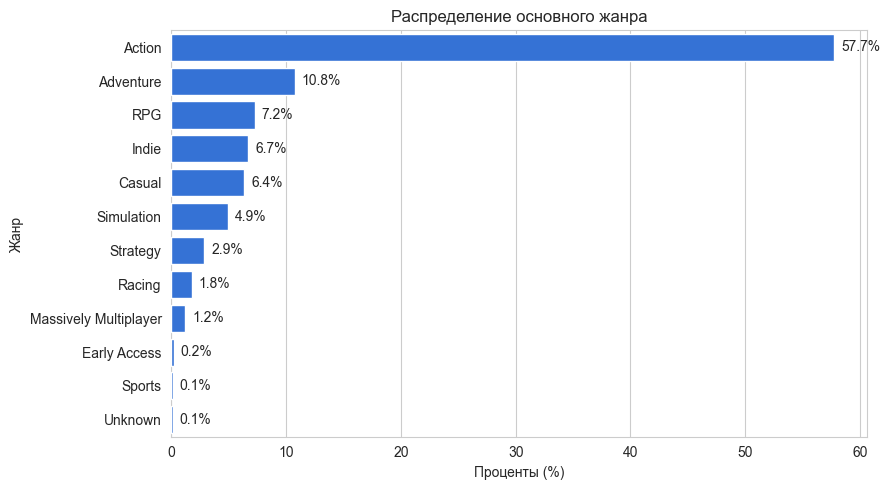

In [8]:
desc_order = df['primary_genre'].value_counts().index
fig, axes = plt.subplots(figsize=(9, 5))
axes.set_axisbelow(True)
sns.countplot(data = df, y = 'primary_genre', ax = axes, zorder=3, order = desc_order, color = '#1a6cf0', stat='percent')
for container in axes.containers:
    axes.bar_label(container, fmt='%.1f%%', padding=5)
plt.title(f'Распределение основного жанра')
plt.xlabel('Проценты (%)')
plt.ylabel('Жанр')
plt.tight_layout()
file_path = os.path.join(output_dir, f'Count_plot_primary_genre.png')
plt.savefig(file_path)
plt.show()

Построим столбчатую диаграмму распределения 10 популярных жанров из поля `all_tags`

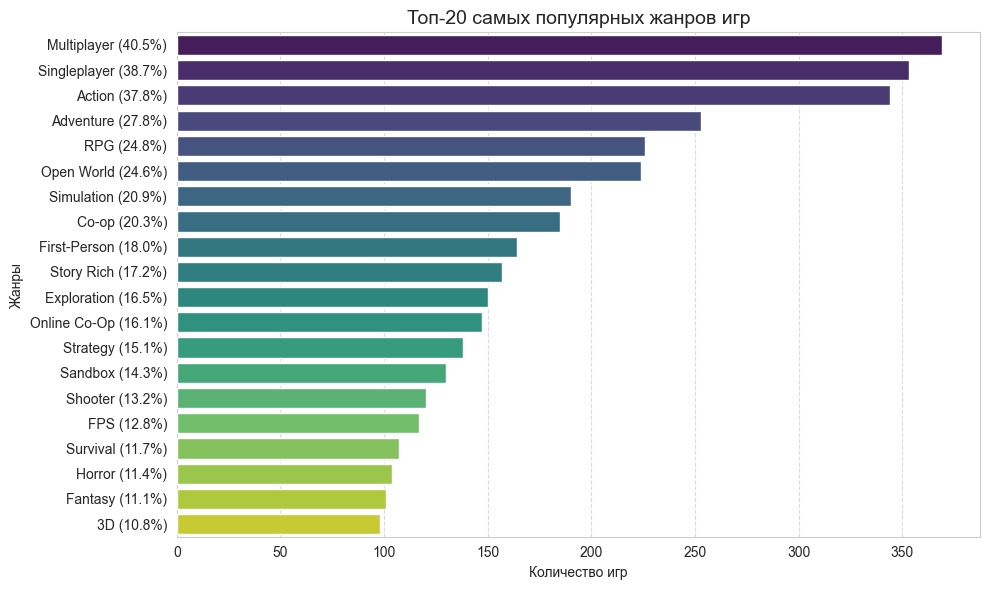

In [9]:
total_games = df.shape[0]
genre_series = df['all_tags'].str.split(';').explode()
top_genre = genre_series.value_counts().head(20)
top_genre.index = [f'{genre} ({(count / total_games) * 100:.1f}%)' for genre, count in top_genre.items()]
fig, axes = plt.subplots(figsize=(10, 6))
axes.set_axisbelow(True)
sns.barplot(x = top_genre.values, y = top_genre.index, ax = axes, palette='viridis', hue = top_genre.index, legend= False, zorder=3)
axes.grid(axis = 'x', linestyle='--', alpha=0.7, zorder=0)
plt.title('Топ-20 самых популярных жанров игр', fontsize=14)
plt.xlabel('Количество игр')
plt.ylabel('Жанры')
plt.tight_layout()
file_path = os.path.join(output_dir, f'Bar_plot_popular_genre.png')
plt.savefig(file_path)
plt.show()

### Сравнения

Сравнение средней оценки бесплатных и платных игр

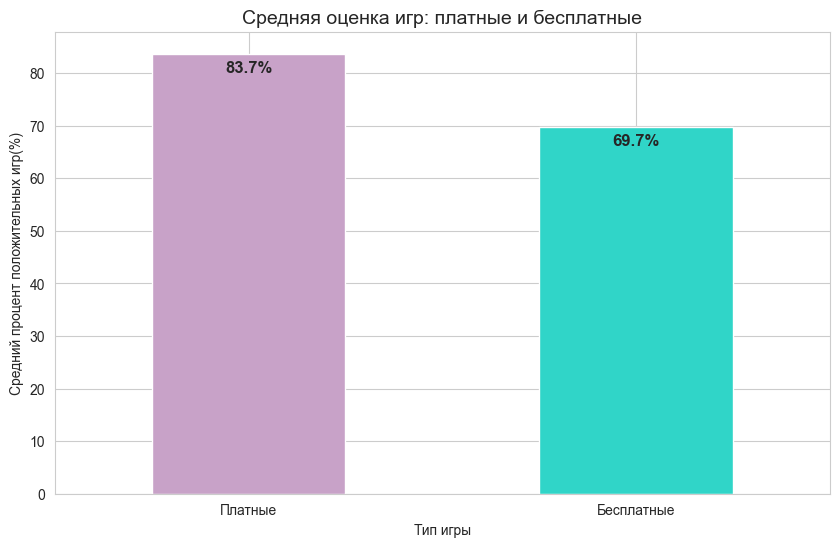

In [10]:
avg_score_by_free = df.groupby('is_free')['review_score_pct'].mean()
avg_score_by_free.index = ['Платные','Бесплатные']
plt.subplots(figsize=(10, 6))
avg_score_by_free.plot(kind = 'bar', color = ['#C8A2C8', '#30D5C8'])
for i, v in enumerate(avg_score_by_free):
    plt.text(i, v - 3.5, f'{v:.1f}%', ha='center', fontsize=12, fontweight='bold')
plt.title('Средняя оценка игр: платные и бесплатные', fontsize=14)
plt.xticks(rotation = 0)
plt.xlabel('Тип игры')
plt.ylabel('Средний процент положительных игр(%)')
file_path = os.path.join(output_dir, f'Plot_avg_score_by_free.png')
plt.savefig(file_path)
plt.show()

Можно заметить, что в среднем оценки у платных игр выше. Казалось бы люди должны быть строже к ним  <br>
Исследуем распределение детальнее с помощью boxplot.

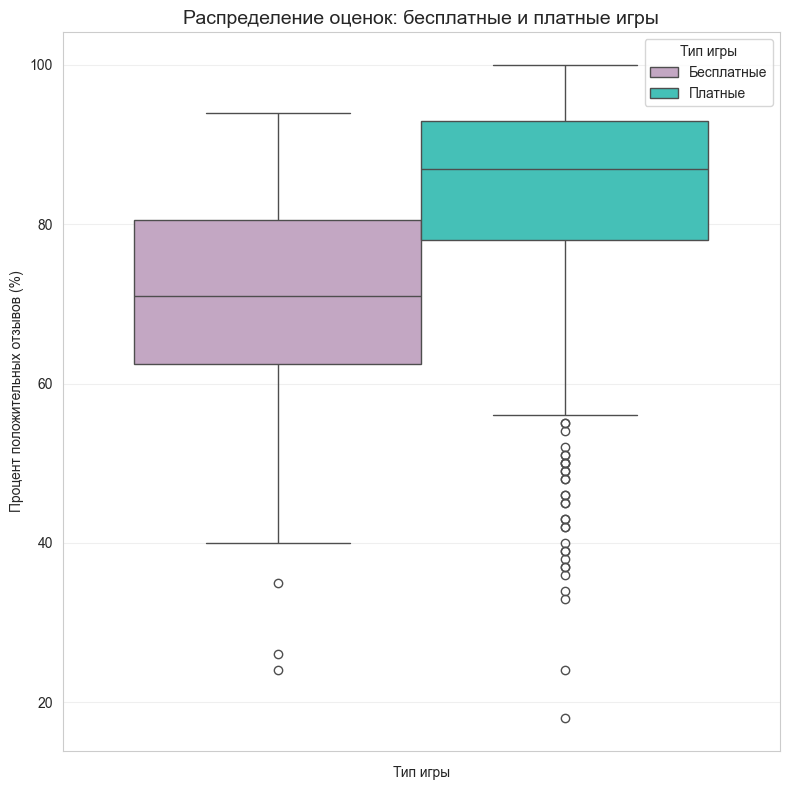

In [11]:
df['is_free_label'] = df['is_free'].map({True: 'Бесплатные', False: 'Платные'}) #Создание подписей
plt.figure(figsize=(8, 8))
sns.boxplot(data = df,  hue= 'is_free_label', y = 'review_score_pct', palette = ['#C8A2C8', '#30D5C8'])
plt.title('Распределение оценок: бесплатные и платные игры', fontsize=14)
plt.xticks(rotation = 0)
plt.legend(title= 'Тип игры')
plt.xlabel('Тип игры')
plt.ylabel('Процент положительных отзывов (%)')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
file_path = os.path.join(output_dir, f'Box_plot_avg_score_by_free.png')
plt.savefig(file_path)
plt.show()

1. **Платные игры получают более высокие оценки, чем бесплатные**<br>
У платных игр выше медиана, а сам ящик смещен сильнее вверх, к зоне 80–90% положительных отзывов. Бесплатные игры имеют более низкие оценки и гораздо больший разброс.<br>
2. **Оценки бесплатных игр смещены вниз.** Широкий ящик и длинные нижний ус у бесплатных говорит о большом разбросе в низких оценках у бесплатных игр. В то время как у платных игр распределение ограничено естественным потолком в 100% положительных отзывов, а распределены они плотнее.<br>
3. **Стабильность платного сегмента.** Выбросы у платных игр подтверждают гипотезу о качественности проектов, но сигнализируют о наличие единичных провальных проектов. У бесплатных аналогичные оценки являются нормой, укладываясь в общий диапазон внутри уса.

Оценка в зависимости от года релиза

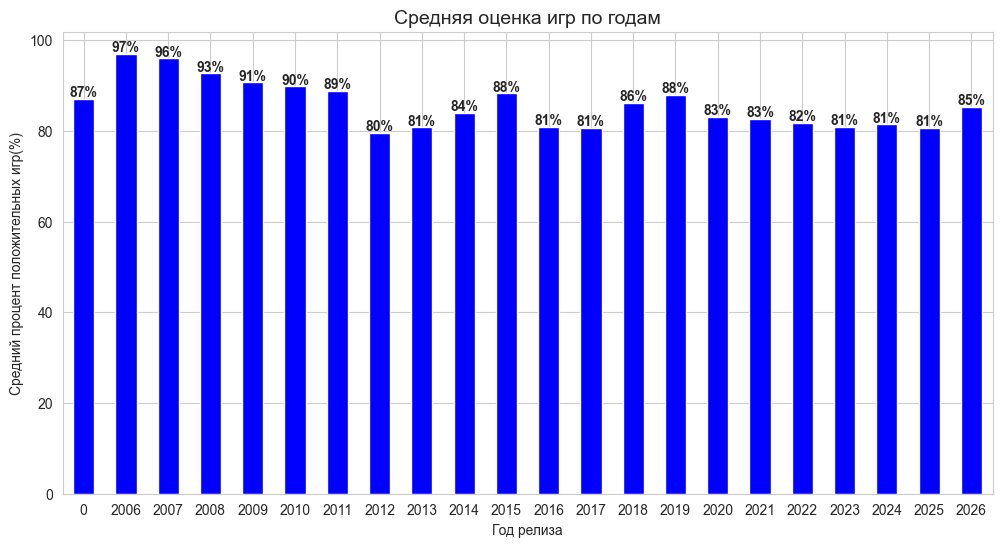

In [12]:
avg_score_by_year = df.groupby('release_year')['review_score_pct'].mean()
plt.subplots(figsize=(12, 6))
avg_score_by_year.plot(kind = 'bar', color = 'blue')
for i, v in enumerate(avg_score_by_year):
    plt.text(i, v + 0.5, f'{v:.0f}%', ha='center', fontsize=10, fontweight='bold')
plt.title('Средняя оценка игр по годам', fontsize=14)
plt.xticks(rotation = 0)
plt.xlabel('Год релиза')
plt.ylabel('Средний процент положительных игр(%)')
file_path = os.path.join(output_dir, f'Plot_avg_score_by_year.png')
plt.savefig(file_path)
plt.show()

Можем заметить тенденцию снижения средней оценки.

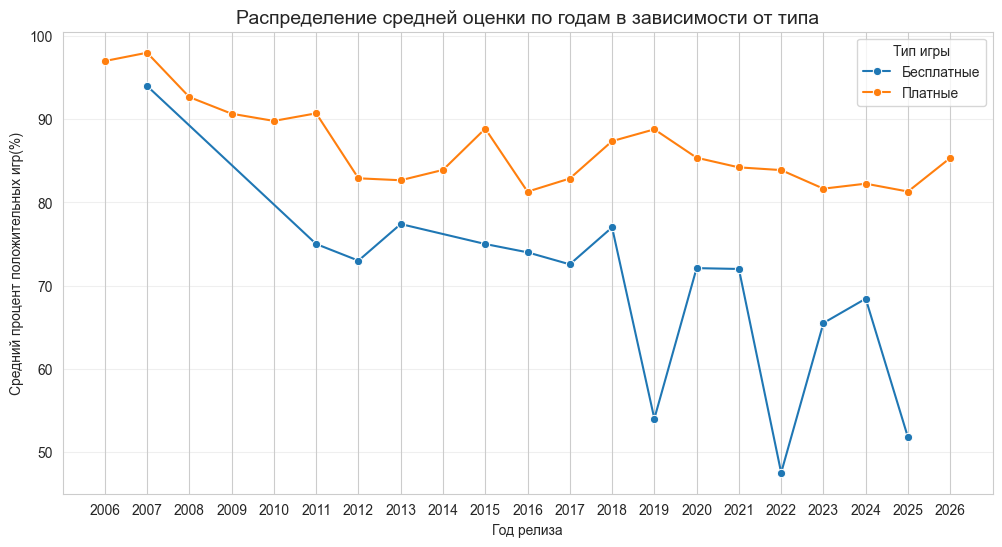

In [13]:
plt.subplots(figsize=(12, 6))
df_filtered = df[df['release_year']!= 0]
years = sorted(df_filtered['release_year'].dropna().unique().astype(int))

sns.lineplot(data = df_filtered, y = 'review_score_pct', x = 'release_year', hue  = 'is_free_label', marker='o', errorbar=None)
plt.title('Распределение средней оценки по годам в зависимости от типа', fontsize=14)
plt.legend(title= 'Тип игры')
plt.xticks(years, labels = years, rotation = 0)
plt.xlabel('Год релиза')
plt.ylabel('Средний процент положительных игр(%)')
plt.grid(axis='y', alpha=0.3)
file_path = os.path.join(output_dir, f'Line_plot_avg_score_year_by_free.png')
plt.savefig(file_path)
plt.show()

При рассмотрении динамики средней оценки по годам с разбивкой на тип игры тенденция снижения оценки сохраняется. Однако средняя оценка платных игр стабильнее бесплатных. У группы бесплатных явные провалы оценок в 2019, 2022 и 2025. <br>
Также за ряд годов отсутствуют бесплатные игры.

In [14]:
# Посчитаем количество игр каждого типа по годам
print(df_filtered.groupby(['release_year', 'is_free_label']).size())

release_year  is_free_label
2006          Платные            1
2007          Бесплатные         1
              Платные            1
2008          Платные            3
2009          Платные            6
2010          Платные            5
2011          Бесплатные         1
              Платные            7
2012          Бесплатные         5
              Платные           10
2013          Бесплатные         5
              Платные            9
2014          Платные           11
2015          Бесплатные         1
              Платные           23
2016          Бесплатные         2
              Платные           34
2017          Бесплатные         9
              Платные           32
2018          Бесплатные         5
              Платные           38
2019          Бесплатные         1
              Платные           38
2020          Бесплатные        10
              Платные           48
2021          Бесплатные         8
              Платные           56
2022          Бесплатные   

Бесплатные игры действительно отсутствуют в ряде годов. Датасет содержит 1000 популярных игр на момент выборки, значит популярных игр этих годов в момент сбора данных не оказалось.

Популярность (`Estimated_Owners`, `24h_Peak_Players`) по жанрам

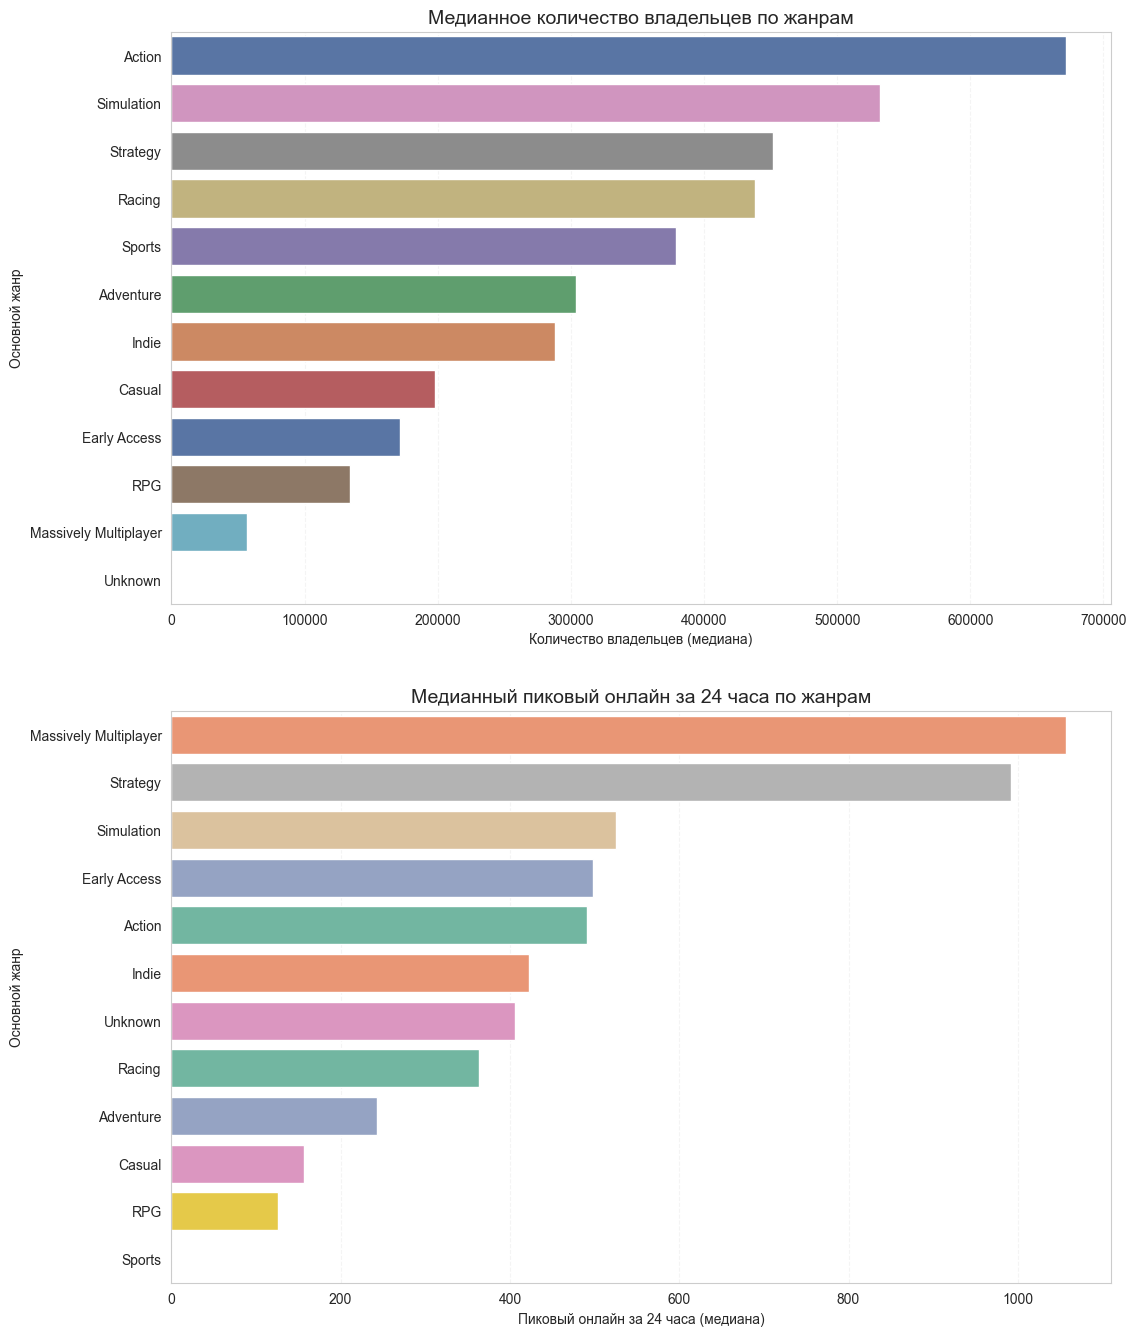

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(12, 14))
order_owners = df.groupby('primary_genre')['estimated_owners'].median().sort_values(ascending = False).index
sns.barplot(
    data = df,
    x = 'estimated_owners',
    y ='primary_genre',
    ax = axes[0],
    estimator = 'median',
    errorbar = None,
    palette= 'deep',
    hue = 'primary_genre',
    legend = False,
    order = order_owners)

axes[0].set_title('Медианное количество владельцев по жанрам', fontsize=14)
axes[0].set_xlabel('Количество владельцев (медиана)')
axes[0].set_ylabel('Основной жанр')
axes[0].grid(axis='x', linestyle='--', alpha=0.2, zorder=0)

order_peak = df.groupby('primary_genre')['24h_peak_players'].median().sort_values(ascending = False).index
sns.barplot(
    data = df,
    x = '24h_peak_players',
    y = 'primary_genre',
    ax = axes[1],
    estimator = 'median',
    palette='Set2',
    errorbar = None,
    hue = 'primary_genre',
    legend = False,
    order = order_peak)

axes[1].set_title('Медианный пиковый онлайн за 24 часа по жанрам', fontsize=14)
axes[1].set_xlabel('Пиковый онлайн за 24 часа (медиана)')
axes[1].set_ylabel('Основной жанр')
axes[1].grid(axis='x', linestyle='--', alpha=0.2, zorder=0)
plt.tight_layout(pad = 3)
file_path = os.path.join(output_dir, f'Bar_plot_genre_by_own_peak.png')
plt.show()

При вычислении была использована именно медиана, для того чтобы снизить перекос в сторону игр огромным онлайнов и/или числом владельцев.

### Корреляции

Построим матрицу корреляций

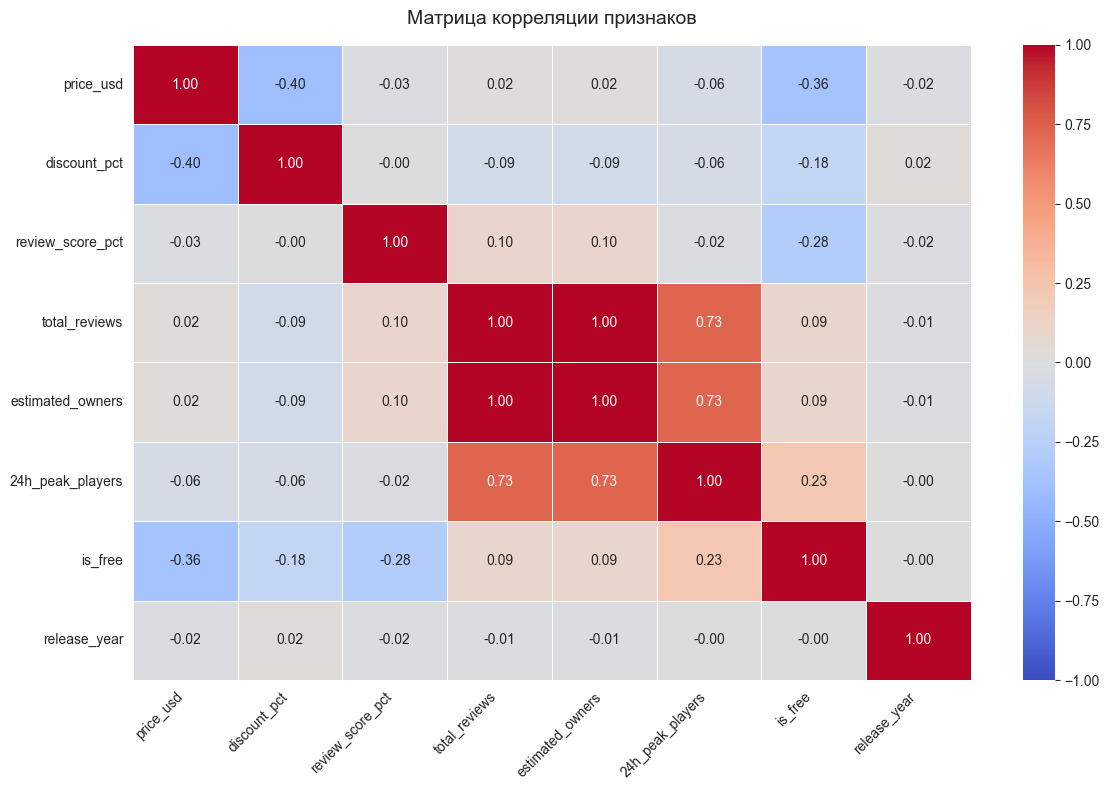

                  price_usd  discount_pct  review_score_pct  total_reviews  \
price_usd              1.00         -0.40             -0.03           0.02   
discount_pct          -0.40          1.00             -0.00          -0.09   
review_score_pct      -0.03         -0.00              1.00           0.10   
total_reviews          0.02         -0.09              0.10           1.00   
estimated_owners       0.02         -0.09              0.10           1.00   
24h_peak_players      -0.06         -0.06             -0.02           0.73   
is_free               -0.36         -0.18             -0.28           0.09   
release_year          -0.02          0.02             -0.02          -0.01   

                  estimated_owners  24h_peak_players  is_free  release_year  
price_usd                     0.02             -0.06    -0.36         -0.02  
discount_pct                 -0.09             -0.06    -0.18          0.02  
review_score_pct              0.10             -0.02    -0.28  

In [16]:
df_filt = df.drop(columns=['full_price_usd', 'appid'])
corr_matrix = df_filt.corr(numeric_only=True).round(2)
plt.figure(figsize=(12, 8))
sns.heatmap(
    data = corr_matrix,
    vmin = -1,
    vmax = 1,
    annot = True,
    fmt = '.2f',
    cmap = 'coolwarm',
    linewidths = 0.5
)

plt.title('Матрица корреляции признаков', fontsize=14, pad = 15)
plt.xticks(rotation = 45, ha = 'right')
plt.yticks(rotation = 0)
plt.tight_layout()
file_path = os.path.join(output_dir, 'Hitmap_corr_matrix.png')
plt.savefig(file_path)
plt.show()
print(corr_matrix)

#### Основные инсайты матрицы корреляции:<br>
- **Идеальная линейная связь** (1.00) между total_reviews и estimated_owners: метрики полностью дублируют друг друга. Вероятно, количество владельцев рассчитывалось как производная от числа отзывов. Одну из колонок следует исключить при дальнейшем моделировании для избежания мультиколлинеарности.<br>
- **Сильная положительная связь** (0.73) между total_reviews и 24h_peak_players: текущая активность аудитории  напрямую масштабируется пропорционально накопленной базе отзывов.<br>
- **Умеренная отрицательная связь** (-0.28) между review_score_pct и is_free: статус бесплатной игры снижает средний процент положительных отзывов, что подтверждает ранее сделанные выводы по диаграмме размаха (box plot).<br>
- **Отсутствие связи** (-0.03) между review_score_pct и price_usd: стоимость игры в долларах никак не влияет на финальную оценку пользователей. <br>
- Также -0.09 между discount_pct vs total_reviews говорит о том, что скидка не генерирует огромную популярность(количество отзывов). Между review_score_pct vs total_reviews корреляция всего 0.10, количество написанных отзывов не зависит от того, насколько сильно хвалят игру.

Проверим с помощью scatter-plot характер связи трех пар:<br>
1. price_usd vs review_score_pct — это визуализация проверки «Влияет ли цена на оценку?».
2. discount_pct vs total_reviews — это визуализация проверки «Помогают ли скидки привлечь огромную массу игроков, которые оставят отзывы?».
3. review_score_pct vs total_reviews — это визуализация проверки «Правда ли, что самые популярные игры с кучей отзывов имеют только высокие оценки?».<br>
Связь между ними могла быть нелинейной, поэтому коэффициент Пирсона мог не учесть их. Также scatter-plot поможет выделить кластеры, где возможна корреляция.

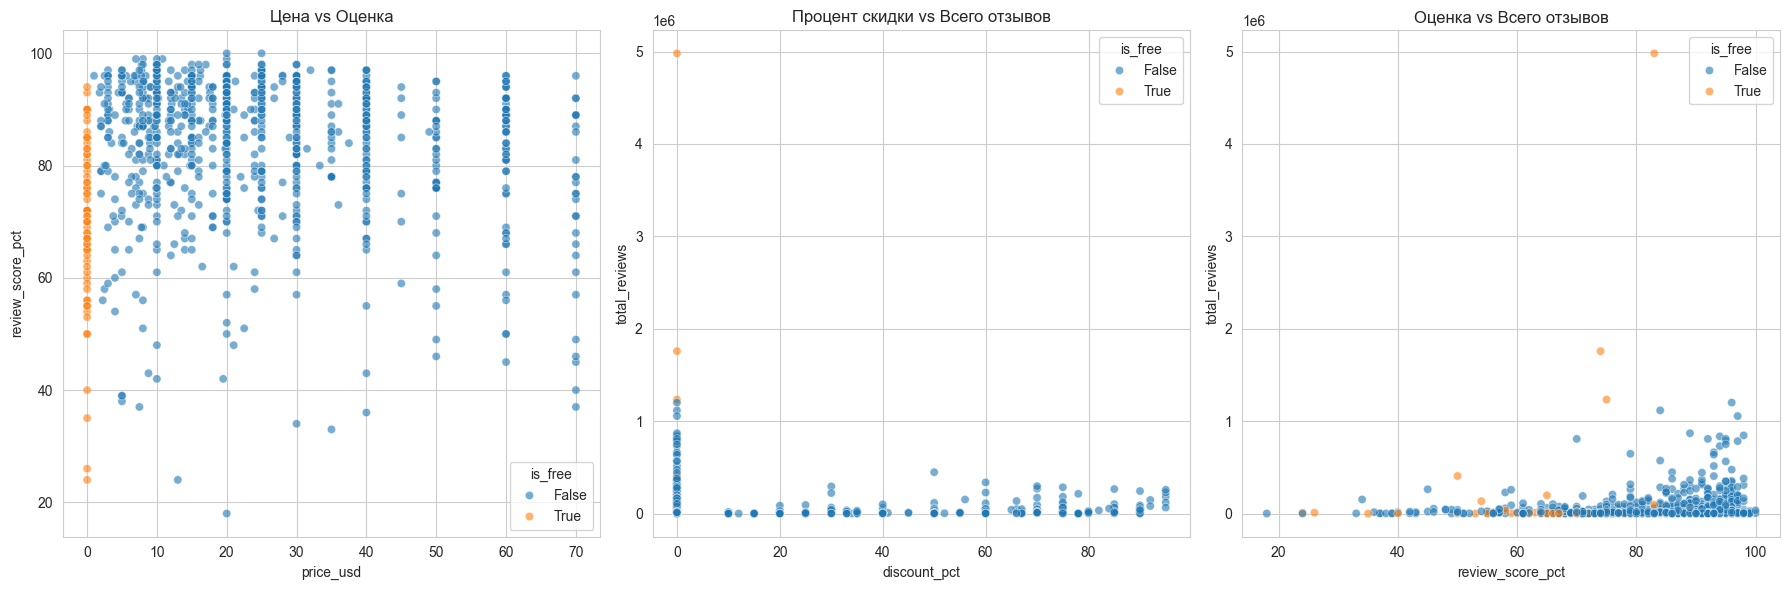

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Пара 1: Цена vs Оценка
sns.scatterplot(data=df, x='price_usd', y='review_score_pct', hue='is_free', alpha=0.6, ax=axes[0])
axes[0].set_title('Цена vs Оценка')

# Пара 2: Скидка vs Всего отзывов
sns.scatterplot(data=df, x='discount_pct', y='total_reviews', hue='is_free', alpha=0.6, ax=axes[1])
axes[1].set_title('Процент скидки vs Всего отзывов')

# Пара 3: Оценка vs Всего отзывов
sns.scatterplot(data=df, x='review_score_pct', y='total_reviews', hue='is_free', alpha=0.6, ax=axes[2])
axes[2].set_title('Оценка vs Всего отзывов')

plt.tight_layout()
file_path = os.path.join(output_dir, f'Scatter_plot_corr_by_free.png')
plt.savefig(file_path)
plt.show()

1. **График Цена vs Оценка** <br>
Четко прослеживаются вертикальные линии по популярным ценникам. Оценки бесплатных игр размазы по всей высоте. Среди них как отличные, так и провальные проекты.
2. **График Процент скидки vs Всего отзывов** <br>
Почти все точки лежат около нуля, скидка сама по себе не дает отзывы. Но на нулевой отметке скидки (discount_pct = 0) есть два безумных оранжевых выброса, улетающих вверх до 5 миллионов отзывов. Самые популярные бесплатные игры ломают общую корреляцию, дают миллионы отзывов при фактической нулевой скидке.
3. **График Оценка vs Всего отзывов** <br>
Игры супер-хиты с миллионными масштабами отзывов практически всегда имеют рейтинг выше 70-80%. Вы не найдете в Steam игру с 1 миллионом отзывов и рейтингом 30%. Популярность требует качества. Опять же замечены бесплатные хиты с огромным числом отзывов.

In [18]:
# Фильтруем супер-хиты и выводим их названия, отзывы и оценки
super_hits = df[df['total_reviews'] > 1000000][['name', 'total_reviews', 'review_score_pct', 'is_free']]
print(super_hits)

                               name  total_reviews  review_score_pct  is_free
0                  Counter-Strike 2        4980365                83     True
16   Tom Clancy's Rainbow Six Siege        1234092                75     True
28                             Rust        1116689                84    False
57              PUBG: BATTLEGROUNDS        1757549                74     True
158                        Terraria        1201073                96    False
226                     Garry's Mod        1055266                97    False


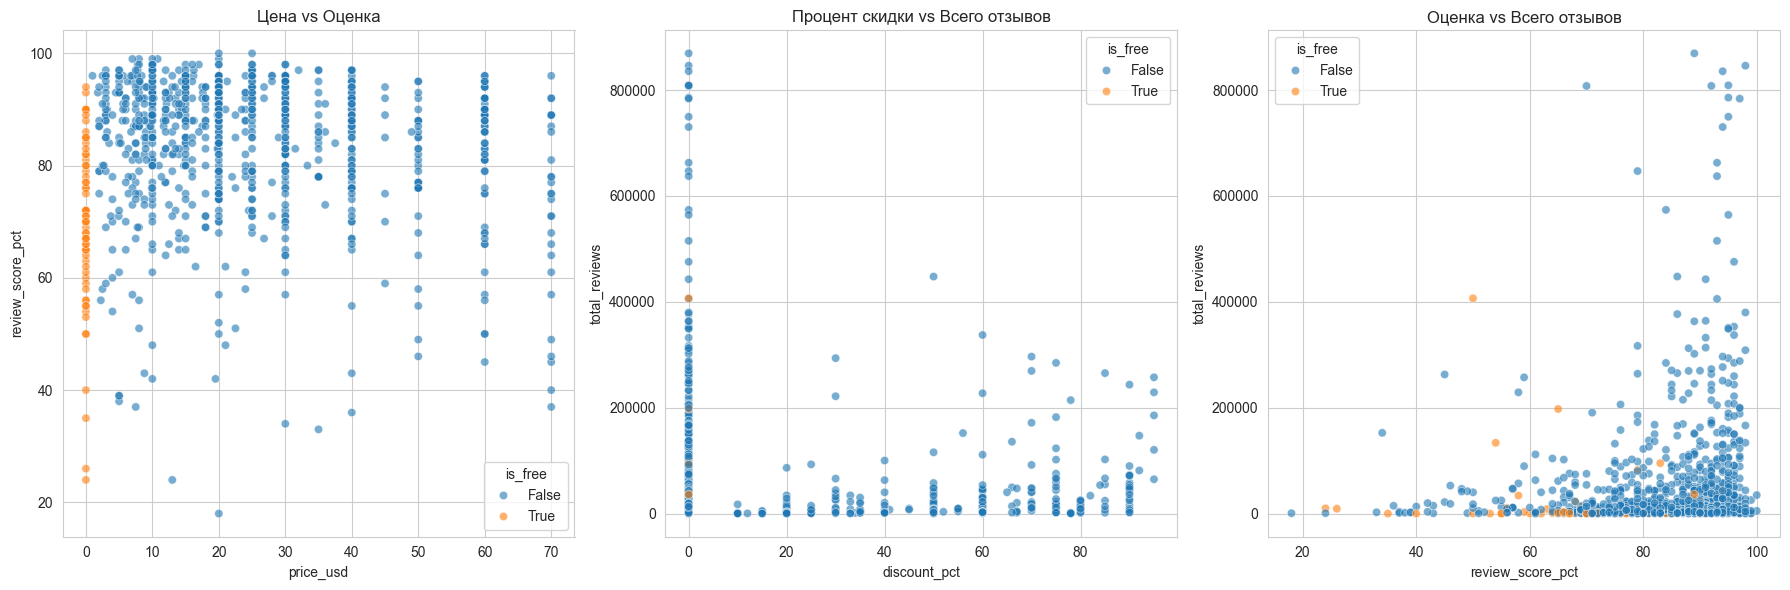

In [19]:
df_no_giants = df[df['total_reviews']< 1000000]
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

sns.scatterplot(data=df_no_giants, x='price_usd', y='review_score_pct', hue='is_free', alpha=0.6, ax=axes[0])
axes[0].set_title('Цена vs Оценка')

sns.scatterplot(data=df_no_giants, x='discount_pct', y='total_reviews', hue='is_free', alpha=0.6, ax=axes[1])
axes[1].set_title('Процент скидки vs Всего отзывов')

sns.scatterplot(data=df_no_giants, x='review_score_pct', y='total_reviews', hue='is_free', alpha=0.6, ax=axes[2])
axes[2].set_title('Оценка vs Всего отзывов')

plt.tight_layout()
file_path = os.path.join(output_dir, f'Scatter_plot_corr_by_free_no_giants.png')
plt.savefig(file_path)
plt.show()

Фильтрация игр-гигантов (свыше 1 млн отзывов) позволила скорректировать масштаб осей и детально изучить распределение основной массы успешных проектов. Изменение масштаба подтвердило, что экспоненциальный рост популярности (количества отзывов) начинается строго после преодоления барьера в 80% положительных оценок. При этом **самые популярные игры удерживают лидерство без применения скидочных механик**

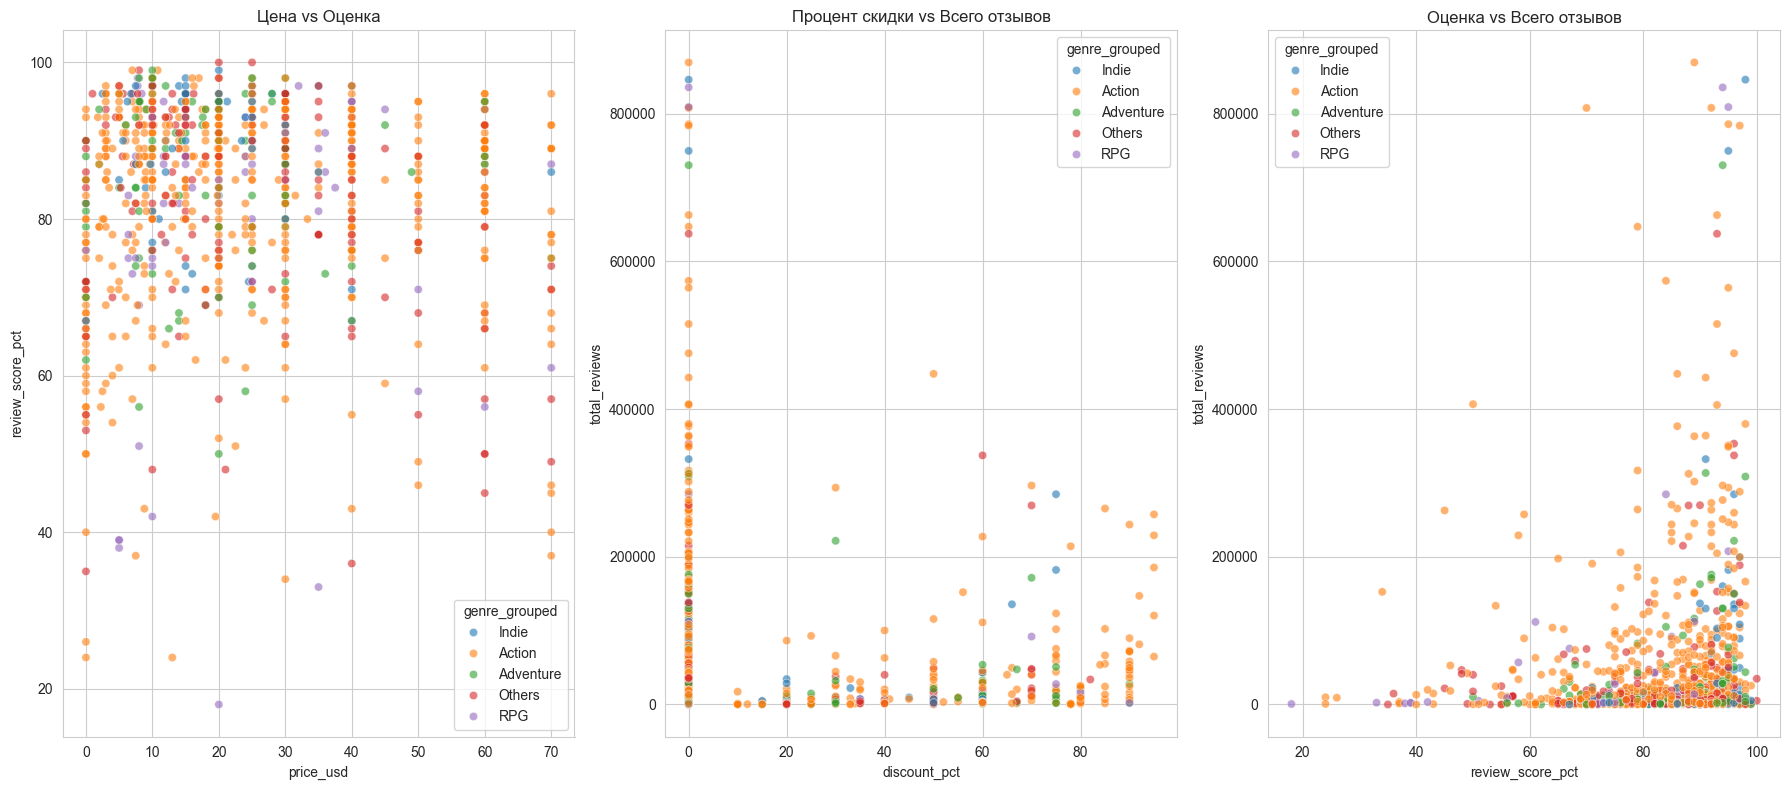

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 8))
top_genre = df_no_giants['primary_genre'].value_counts().nlargest(4).index
df_no_giants['genre_grouped'] = df_no_giants['primary_genre'].apply(lambda x: x if x in top_genre else 'Others')
# Пара 1: Цена vs Оценка
sns.scatterplot(data=df_no_giants, x='price_usd', y='review_score_pct', hue='genre_grouped', alpha=0.6, ax=axes[0])
axes[0].set_title('Цена vs Оценка')

# Пара 2: Скидка vs Всего отзывов
sns.scatterplot(data=df_no_giants, x='discount_pct', y='total_reviews', hue='genre_grouped', alpha=0.6, ax=axes[1])
axes[1].set_title('Процент скидки vs Всего отзывов')

# Пара 3: Оценка vs Всего отзывов
sns.scatterplot(data=df_no_giants, x='review_score_pct', y='total_reviews', hue='genre_grouped', alpha=0.6, ax=axes[2])
axes[2].set_title('Оценка vs Всего отзывов')
plt.tight_layout()
file_path = os.path.join(output_dir, f'Scatter_plot_corr_by_genre.png')
plt.savefig(file_path)
plt.show()

### Тренды
Количество выпущенных игр по годам / месяцам

In [21]:
df_temp = df
df_temp['release_month'] = df_temp['release_date'].dt.month.astype('Int64').fillna(0)
games_by_ym = df.groupby(['release_year','release_month']).size()

matrix_df = (
    games_by_ym.reset_index(name = 'Количество').pivot(index = 'release_year', columns = 'release_month', values = 'Количество').fillna(0)
)
matrix_df['by_year'] = matrix_df.sum(axis = 1)
matrix_df = matrix_df.astype(int)
matrix_df

release_month,0,1,2,3,4,5,6,7,8,9,10,11,12,by_year
release_year,,,,,,,,,,,,,,
0,1,0,0,0,0,0,0,0,0,0,0,0,0,1
2006,0,0,0,0,0,0,0,0,0,0,0,1,0,1
2007,0,0,0,0,0,0,0,0,0,0,2,0,0,2
2008,0,0,0,0,0,0,0,0,0,0,0,2,1,3
2009,0,1,0,0,0,1,0,0,0,1,0,2,1,6
2010,0,0,0,0,0,1,0,0,0,1,2,1,0,5
2011,0,2,0,0,1,1,1,0,0,0,1,2,0,8
2012,0,1,1,0,0,0,2,0,1,2,3,3,2,15
2013,0,1,0,3,0,1,1,1,3,2,0,1,1,14


Средняя оценка по месяцам релиза (сезонность)

In [22]:
res = df_temp.groupby('release_month')['review_score_pct'].mean()
df_horizontal = res.to_frame(name='Средняя оценка').T.round(1)
df_horizontal

release_month,0,1,2,3,4,5,6,7,8,9,10,11,12
Средняя оценка,87.0,83.6,84.2,84.0,82.1,83.7,82.8,83.3,80.7,84.2,82.0,78.4,83.3


### Статистический план проверки гипотез (Порог значимости: $\alpha = 0.05$)
##### 1. Доминирование жанров «Action», «RPG», «Indie» по количеству игроков

* Параметры: Категории (genre) vs Количественная метрика (estimated_owners или total_reviews).
* Тест: Критерий Краскела-Уоллиса (stats.kruskal) для сравнения всех 11 жанров, а затем Пост-хок тест Данна (sp.posthoc_dunn из библиотеки scikit-posthocs).
* Логика: Критерий Краскела-Уоллиса покажет, есть ли в принципе разница между жанрами. Тест Данна попарно сравнит жанры и математически докажет, находятся ли Action, RPG и Indie на вершине со значимым отрывом от остальных.

In [23]:
groups = [group['total_reviews']for name, group in df.groupby('primary_genre')]
res = stats.kruskal(*groups, nan_policy = 'omit')
print(f'Статистика: {res.statistic.round(4)},p_value: {res.pvalue.round(4)}')

Статистика: 46.6178,p_value: 0.0


In [24]:
test_result = pg.kruskal(data=df, dv='total_reviews', between='primary_genre')
print(test_result)

                Source  ddof1         H     p_unc
Kruskal  primary_genre     11  46.61784  0.000003


Получено p_value < 0.05 -> Разница статистически значима. Жанр игры имеет значение для количества отзывов. Проведем пост-хок тест Данна:

                         Action  Adventure    Casual  Early Access  Indie  \
Action                 1.000000   0.032516  0.005869           1.0    1.0   
Adventure              0.032516   1.000000  1.000000           1.0    1.0   
Casual                 0.005869   1.000000  1.000000           1.0    1.0   
Early Access           1.000000   1.000000  1.000000           1.0    1.0   
Indie                  1.000000   1.000000  1.000000           1.0    1.0   
Massively Multiplayer  0.142203   1.000000  1.000000           1.0    1.0   
RPG                    0.003378   1.000000  1.000000           1.0    1.0   
Racing                 1.000000   1.000000  1.000000           1.0    1.0   
Simulation             1.000000   1.000000  1.000000           1.0    1.0   
Sports                 1.000000   1.000000  1.000000           1.0    1.0   
Strategy               1.000000   1.000000  1.000000           1.0    1.0   
Unknown                1.000000   1.000000  1.000000           1.0    1.0   

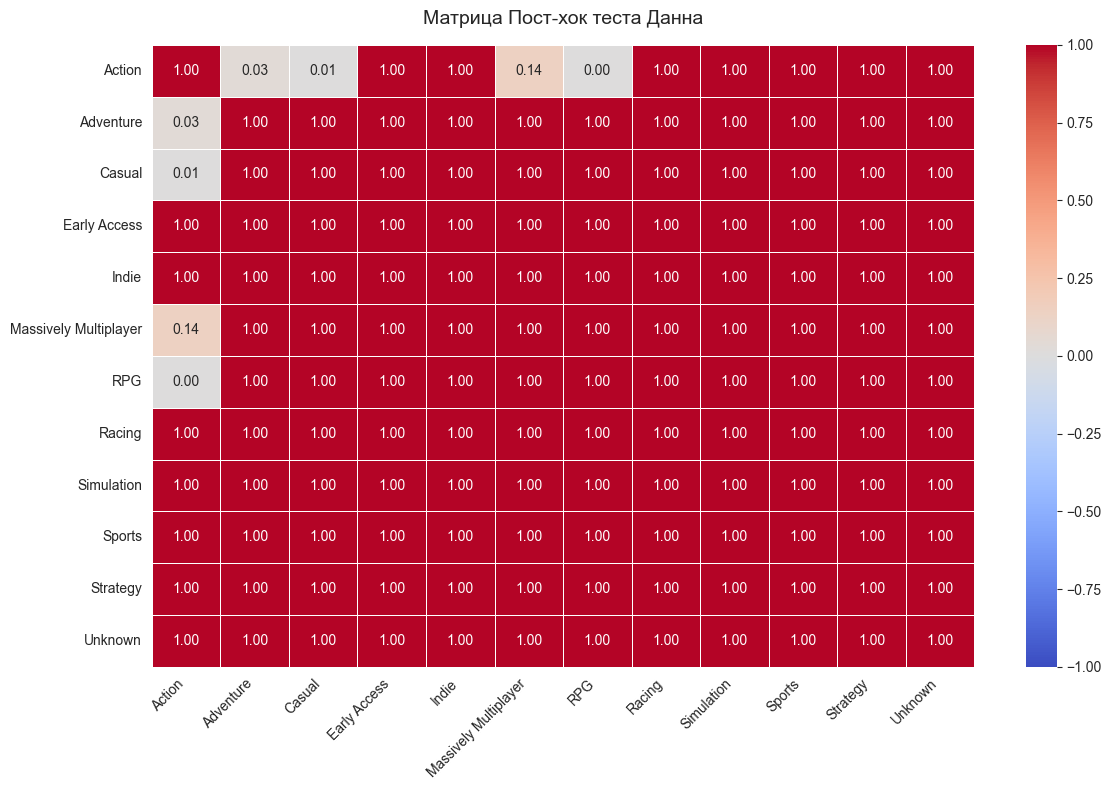

In [25]:
dunn_result = sp.posthoc_dunn(
    a=df,
    val_col='total_reviews',
    group_col='primary_genre',
    p_adjust='bonferroni'
)
print(dunn_result)
plt.figure(figsize=(12, 8))
sns.heatmap(
    data = dunn_result,
    vmin = -1,
    vmax = 1,
    annot = True,
    fmt = '.2f',
    cmap = 'coolwarm',
    linewidths = 0.5
)

plt.title('Матрица Пост-хок теста Данна', fontsize=14, pad = 15)
plt.xticks(rotation = 45, ha = 'right')
plt.yticks(rotation = 0)
plt.tight_layout()
file_path = os.path.join(output_dir, 'Ph_dann_test_matrix.png')
plt.savefig(file_path)
plt.show()

Тест Краскела-Уоллиса дал очень низкий pvalue, после тест Данна оказалось, что самый популярный жанр Action сильно оторвался от Adventure, Casual и RPG. <br>
Рынок игр по количеству отзывов однороден для большинства жанров, за исключением Action. Жанр Action является главным статистическим аномалом (или драйвером), который значимо отличается от RPG, Casual и Adventure. Между остальными 9 жанрами никакой статистически значимой разницы в количестве отзывов нет

Построим дополнительно boxplot для ряда выделяющихся жанров: Action, RPG, Casual и Adventure

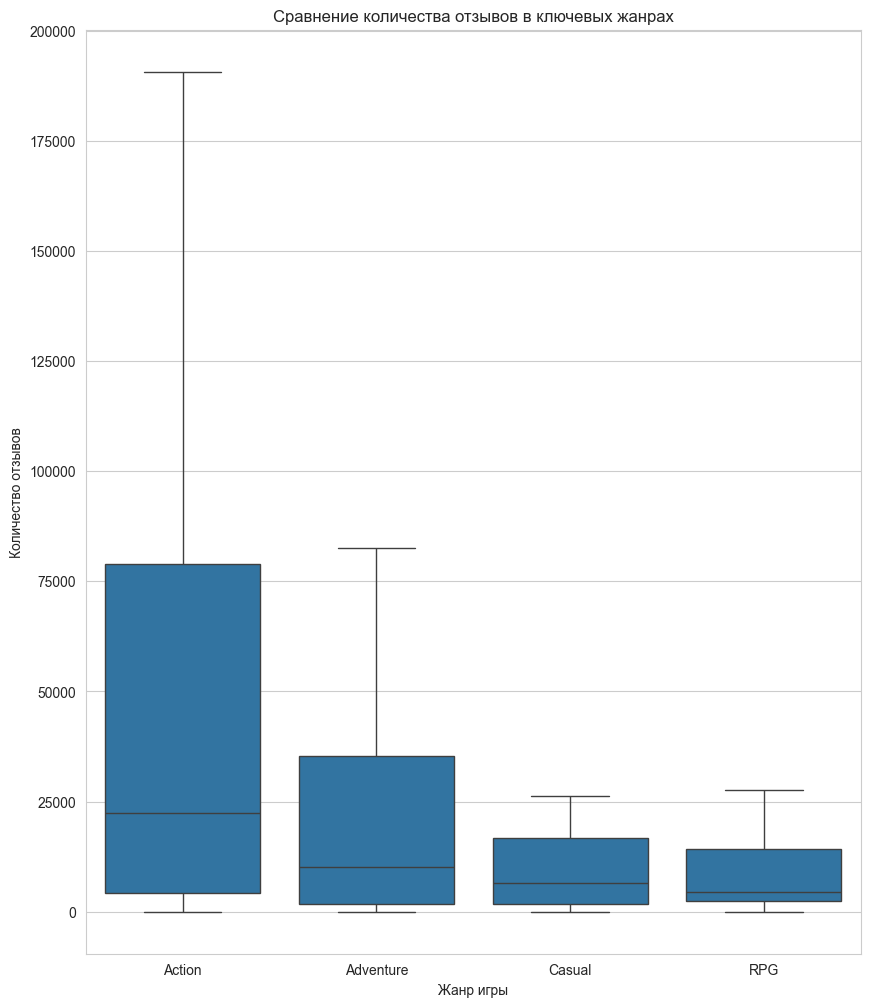

In [26]:
target_genres = ['Action', 'RPG', 'Casual', 'Adventure']
df_filt = df[df['primary_genre'].isin(target_genres)]
plt.figure(figsize=(10, 12))
sns.boxplot(
    data=df_filt,
    x = 'primary_genre',
    y = 'total_reviews',
    showfliers = False
)
plt.title('Сравнение количества отзывов в ключевых жанрах')
plt.xlabel('Жанр игры')
plt.ylabel('Количество отзывов')
plt.show()

По графику видно, что медиана и верхние значения отзывов в жанре Action выше чем других жанров.
Проведенные тесты показали, что несмотря на видимую разницу на барплоте ранее, большинство жанров (Action, Simulation, Strategy, Racing) статистически равны между собой по количеству отзывов/владельцев. Настоящее значимое различие присутствует только между лидером (Action) и аутсайдерами списка (RPG, Casual, Adventure).

##### 2. Высокая скидка (%) не всегда коррелирует с ростом оценок

* Параметры: Количественная (discount_pct) vs Количественная (review_score_pct).
* Тест: Коэффициент ранговой корреляции Спирмена (stats.spearmanr).
* Логика: Так как данные ненормальны, вместо Пирсона нужно использовать Спирмена. Если p-value < 0.05, а сам коэффициент близок к нулю (например, от -0.1 до 0.1), это математически докажет вашу гипотезу о том, что скидка не гарантирует рост оценок.

In [27]:
statistic, p_value = stats.spearmanr(df['discount_pct'],df['review_score_pct'], nan_policy = 'omit')
print(f"Коэффициент Спирмена: {statistic:.3f}, p_value: {p_value:.3f}")

Коэффициент Спирмена: -0.014, p_value: 0.662


H0: Скидка НЕ коррелирует с ростом оценок (связи нет). <br>
H1: Скидка коррелирует с ростом оценок (связь есть).<br>
p_value > 0.05 => Принимаем Н0 и связи между скидкой и ростом оценок нет. Связь при этом отрицательная и почти нулевая. То есть скидка — это не определяющий фактор для оценки.<br>
На всякий случай произведем дополнительный расчет, исключив из анализа бесплатные игры с фиксированной скидкой 0%.

In [28]:
filt_df = df[df['is_free']!= True]
statistic, p_value = stats.spearmanr(filt_df['discount_pct'],filt_df['review_score_pct'], nan_policy = 'omit')
print(f"Коэффициент Спирмена: {statistic:.3f}, p_value: {p_value:.3f}")

Коэффициент Спирмена: -0.075, p_value: 0.029


Убрав бесплатные игры видим pvalue < 0.05 => Связь между скидкой и ростом оценок есть. Однако связь очень слабая и отрицательная, с ростом размера скидки число положительных отзывов падает. Но влияние этого фактора минимальное. <br>
Таким образом изначальная гипотеза подтверждается. Скидка не всегда коррелирует с ростом оценок.

##### 3. Дешевизна инди-проектов — один из факторов продаж / высоких оценок

* Параметры: Две подгруппы («Indie» игры vs «Все остальные» жанры).
* Тест: Два U-критерия Манна-Уитни (stats.mannwhitneyu).
* Тест А: Сравнение цен (price_usd) инди и не-инди.
   * Тест Б: Сравнение оценок (review_score_pct) инди и не-инди.
* Логика: Тесты проверят, действительно ли у инди-сегмента средний ранг цены значимо ниже, а средний ранг оценок значимо выше, чем у остального рынка.

In [29]:
indie_group = df[df['primary_genre'] == 'Indie']
non_indie_group = df[df['primary_genre'] != 'Indie']
indie_paid = indie_group[indie_group['is_free'] != True]
non_indie_paid = non_indie_group[non_indie_group['is_free'] != True]

stat_a, p_val_a  = stats.mannwhitneyu(indie_paid['price_usd'], non_indie_paid['price_usd'], nan_policy = 'omit')
stat_b, p_val_b  = stats.mannwhitneyu(indie_group['review_score_pct'], non_indie_group['review_score_pct'], nan_policy = 'omit')
print(f"Тест А (Цены) -> U-stat: {stat_a:.3f}, p-value: {p_val_a:.4f}")
print(f"Тест Б (Оценки) -> U-stat: {stat_b:.3f}, p-value: {p_val_b:.4f}")

Тест А (Цены) -> U-stat: 20533.500, p-value: 0.1001
Тест Б (Оценки) -> U-stat: 35896.500, p-value: 0.0000


In [30]:
# Проверяем направление разницы для цен
print(f"Медианная цена Indie: {indie_paid['price_usd'].median()}")
print(f"Медианная цена остальных: {non_indie_group['price_usd'].median()}")

# Проверяем направление разницы для оценок
print(f"Медианная оценка Indie: {indie_group['review_score_pct'].median()}")
print(f"Медианная оценка остальных: {non_indie_group['review_score_pct'].median()}")


Медианная цена Indie: 19.99
Медианная цена остальных: 19.99
Медианная оценка Indie: 93.0
Медианная оценка остальных: 86.0


Н0: Связи нет <br>
Н1: Связь есть <br>
**Тест А:** <br>
pvalue > 0.05 => Мы не имеем оснований отвергнуть нулевую гипотезу (Н0). Разница в ценах между платными инди-проектами и остальными платными играми статистически незначима. Предположение о том, что «дешевизна инди-проектов является фактором» математически не подтверждается. Также медиана Инди и не Инди игр равна. <br>
**Тест Б:** <br>
pvalue < 0.05 => Разница в оценках абсолютно статистически значима. Мы уверенно отвергаем нулевую гипотезу (Н0) о равенстве распределений. Жанр (Инди vs Остальные) действительно сильно влияет на финальный рейтинг игры. Медиана Инди выше остальных. <br>

##### 4. AAA-проекты покупают несмотря на цену

* Параметры: Подгруппа AAA-игр (можно выделить по фильтру price_usd >= 50 или developer из топа) vs Остальные игры.
* Тест: Коэффициент корреляции Спирмена (stats.spearmanr) между price_usd и estimated_owners только внутри группы AAA.
* Логика: Если внутри дорогого сегмента корреляция между ценой и объемом продаж окажется около нуля (p-value > 0.05) или даже слабо положительной, значит, для ААА-аудитории высокий ценник действительно не является барьером для покупки.


In [35]:
aaa_group = df[df['full_price_usd'] >= 50]
statistic, p_value = stats.spearmanr(aaa_group['full_price_usd'],aaa_group['estimated_owners'], nan_policy = 'omit')
print(f"Коэффициент Спирмена: {statistic:.3f}, p_value: {p_value:.3f}")

Коэффициент Спирмена: -0.031, p_value: 0.736


Н0: Связи нет. Цена не влияет на объем продаж. <br>
Н1: Между ценой игры и объёмом её аудитории внутри AAA-сегмента существует монотонная взаимосвязь. <br>
Гипотеза полностью подтвердилась. Так как pvalue > 0.05 ,то не имеем оснований отвергнуть нулевую гипотезу. Между базовой ценой игры и объемом её аудитории внутри премиум-сегмента ($50+) нет абсолютно никакой статистической взаимосвязи. Для покупателей AAA-игр в Steam разница в цене не выступает барьером для покупки.  <br>
**Спрос в этом секторе неэластичен по цене: геймеры ориентируются на бренд, оценки, жанр и маркетинг, а не на ценник.**

In [34]:
statistic, p_value = stats.spearmanr(df['price_usd'],df['estimated_owners'], nan_policy = 'omit')
print(f"Коэффициент Спирмена: {statistic:.3f}, p_value: {p_value:.3f}")

Коэффициент Спирмена: 0.262, p_value: 0.000


Положительная корреляция на полной выборке (0.262, p-value < 0.05) отражает разницу в масштабе между успешными инди-хитами и крупнобюджетными релизами. Даже среди самых популярных игр Steam действует правило: проекты с более высоким бюджетом  продаются по более высокой цене и при этом привлекают максимальную по объему аудиторию, сдвигая общую корреляцию вверх. Однако, как только мы сужаем выборку исключительно до AAA-сегмента (>= 50$), эта связь полностью исчезает (-0.031, p-value > 0.05). Это доказывает, что на самом вершине рынка ценовая конкуренция отключается: геймеру одинаково не важно, стоит ли главный хит года 50 или 70.

##### 5. Чем выше цена, тем выше ожидания $\rightarrow$ оценки могут быть ниже

* Параметры: Количественная (price_usd) vs Количественная (review_score_pct).
* Тест: Коэффициент корреляции Спирмена (stats.spearmanr).
* Логика: Вы этот тест уже провели через матрицу корреляции (Пирсона) и скаттерплот. Спирмен поставит финальную точку. Знак коэффициента (плюс или минус) покажет направление связи. Отрицательный коэффициент подтвердил бы гипотезу, но ваша матрица уже намекнула на результат около нуля.

In [36]:
statistic, p_value = stats.spearmanr(df['price_usd'],df['review_score_pct'], nan_policy = 'omit')
print(f"Коэффициент Спирмена: {statistic:.3f}, p_value: {p_value:.3f}")

Коэффициент Спирмена: 0.011, p_value: 0.750


Н0: связи нет. Н1: между ценой и оценками отрицательная связь. <br>
Ранее была построена диаграмма рассеивания, тест помогает сделать окончательный вывод. <br>
**Гипотеза №5 о том, что высокий ценник занижает оценки из-за завышенных ожиданий, не подтвердилась**. Наглядно демонстрируется отсутствие как линейной, так и монотонной зависимости (корреляция Спирмена 0.011, p-value > 0.05). В бюджетном сегменте и среди бесплатных игр (is_free = True) наблюдается максимальная дисперсия оценок — от крайне низких до абсолютных хитов.  Напротив, в сегменте $50–$70 распределение смещено вверх: нижний порог оценок поджимается, а плотность точек концентрируется в зоне 60–95%. Это свидетельствует о том, что высокий производственный бюджет AAA-проектов успешно демпфирует давление завышенных ожиданий аудитории.

##### 6. Игры с мультиплеером имеют более высокий 24h_Peak_Players

* Параметры: Бинарный признак (is_multiplayer: 1 или 0) vs Количественная (24h_peak_players).
* Тест: U-критерий Манна-Уитни (stats.mannwhitneyu).
* Логика: Делит игры на два лагеря (с мультиплеером и без) и строго проверяет, значимо ли выше суточный пиковый онлайн у сетевых проектов.

In [57]:
in_tags = df['all_tags'].str.contains('Multiplayer', case=False, na=False)
in_genres = df['primary_genre'].str.contains('Multiplayer', case=False, na=False)
df['is_multiplayer'] = (in_tags | in_genres).astype(int)
df_mult = df[df['is_multiplayer'] == True]
df_nomult = df[df['is_multiplayer'] == False]
stat_a, p_val_a  = stats.mannwhitneyu(df_mult['24h_peak_players'], df_nomult['24h_peak_players'], nan_policy = 'omit')
print(f"Тест -> U-stat: {stat_a:.3f}, p-value: {p_val_a:.4f}")
print("Медианный суточный онлайн мультиплеера:", df_mult['24h_peak_players'].median())
print("Медианный суточный онлайн синглплеера:", df_nomult['24h_peak_players'].median())

Тест -> U-stat: 135147.000, p-value: 0.0000
Медианный суточный онлайн мультиплеера: 852.0
Медианный суточный онлайн синглплеера: 164.0


Н(0): Распределения суточного пикового онлайна (24h_peak_players) у одиночных игр и игр с мультиплеером одинаковы <br>
H(1): Распределение суточного пикового онлайна у мультиплеерных игр сдвинуто в сторону больших значений по сравнению с одиночными играми. <br>
**Гипотеза №6 полностью подтвердилась**. U-критерий Манна-Уитни зафиксировал высокую статистическую значимость различий (pvalue = 0.0000). Медианный суточный онлайн у мультиплеерных проектов составляет 852 человека, тогда как у одиночных игр — всего 164 человека. Даже внутри выборки топ-1000 популярных игр Steam сетевые режимы удерживают ежедневную аудиторию в 5.2 раза эффективнее. Это математически доказывает, что механики реиграбельности создают стабильный и долгосрочный приток игроков, в то время как синглплеерные хиты сталкиваются с быстрым выгоранием аудитории после прохождения основного контента.

In [60]:
in_tags = df['all_tags'].str.contains('Multiplayer', case=False, na=False)
in_genres = df['primary_genre'].str.contains('Multiplayer', case=False, na=False)
df['is_multiplayer'] = (in_tags | in_genres).astype(int)
df_mult_f2p = df[(df['is_multiplayer'] == True) & (df['is_free'] == True)]
df_mult_p2p = df[(df['is_multiplayer'] == True) & (df['is_free'] == False)]
stat_a, p_val_a  = stats.mannwhitneyu(df_mult_f2p['24h_peak_players'], df_mult_p2p['24h_peak_players'], nan_policy = 'omit')
print(f"Тест -> U-stat: {stat_a:.3f}, p-value: {p_val_a:.4f}")
print("Медианный суточный онлайн f2p мультиплеера:", df_mult_f2p['24h_peak_players'].median())
print("Медианный суточный онлайн p2p мультиплеера:", df_mult_p2p['24h_peak_players'].median())

Тест -> U-stat: 11263.500, p-value: 0.0000
Медианный суточный онлайн f2p мультиплеера: 3146.5
Медианный суточный онлайн p2p мультиплеера: 658.0


Дополнительный анализ внутри сетевого сегмента выявил сильный и статистически значимый сдвиг онлайна в пользу Free-to-Play моделей (pvalue = 0.0000).<br>
 Медианный суточный пик бесплатных мультиплеерных игр (3146.5 чел.), почти в 5 раз превосходит показатель платных сетевых проектов (658 чел.). Это математически подтверждает, что устранение финансового барьера на входе (модель F2P) выступает ключевым драйвером масштабирования аудитории. Нулевой порог входа обеспечивает непрерывный приток новых пользователей, что критически важно для сетевых эффектов и удержания высокой базовой активности в долгосрочной перспективе.

##### 7. Бесплатные игры имеют низкие оценки, но огромную аудиторию

* Параметры: Бинарный признак (is_free) vs Две метрики (review_score_pct и estimated_owners).
* Тест: Два U-критерия Манна-Уитни (stats.mannwhitneyu).
* Тест А: Сравнение оценок платных и бесплатных (вы его уже наметили!).
   * Тест Б: Сравнение количества владельцев/отзывов платных и бесплатных.
* Логика: Докажет двойственную природу Free-to-Play: то, что они статистически проигрывают платным по качеству отзывов, но значимо выигрывают по размеру аудитории.

In [63]:
df_mult_f2p = df[df['is_free'] == True]
df_mult_p2p = df[df['is_free'] == False]

stat_a, p_val_a  = stats.mannwhitneyu(df_mult_f2p['review_score_pct'], df_mult_p2p['review_score_pct'], nan_policy = 'omit')
stat_b, p_val_b  = stats.mannwhitneyu(df_mult_f2p['estimated_owners'], df_mult_p2p['estimated_owners'], nan_policy = 'omit')
print(f"Тест А (Оценки)-> U-stat: {stat_a:.3f}, p-value: {p_val_a:.4f}")
print("Медиана оценок Free:", df_mult_f2p['review_score_pct'].median())
print("Медиана оценок Paid:", df_mult_p2p['review_score_pct'].median())
print("-" * 30)
print(f"Тест Б (Владельцы) -> U-stat: {stat_b:.3f}, p-value: {p_val_b:.4f}")
print("Медиана владельцев Free:", df_mult_f2p['estimated_owners'].median())
print("Медиана владельцев Paid:", df_mult_p2p['estimated_owners'].median())

Тест А (Оценки)-> U-stat: 11711.500, p-value: 0.0000
Медиана оценок Free: 71.0
Медиана оценок Paid: 87.0
------------------------------
Тест Б (Владельцы) -> U-stat: 13663.000, p-value: 0.0000
Медиана владельцев Free: 20820.0
Медиана владельцев Paid: 487605.0


Тест А: Н(0): Распределения оценок у платных и бесплатных игр одинаково. <br>
H(1): Распределение оценок у платных и бесплатных игр различны. <br>
Тест Б: Н(0): Распределение владельцев у бесплатных и платных одинаковы. <br>
H(1): Распределение владельцев у бесплатных и платных различны.<br>
**Гипотеза №7 подтвердилась частично, выявив парадоксальную структуру данных** в топ-1000 проектов (pvalue = 0.0000 для обоих тестов). <br>
С одной стороны, бесплатные игры статистически значимо уступают платным по качеству отзывов (медиана 71% против 87%). С другой стороны, вопреки гипотезе, медиана расчетного числа владельцев (estimated_owners) у бесплатных игр оказалась многократно ниже, чем у платных (20.8 тыс. против 487.6 тыс.). <br>
Данная аномалия может носить методологический характер, если оценка владельцев производилась по количеству обзоро. Пользователи активно играют в F2P-проекты (что подтвердил тест при гипотезе 6), но значительно реже оставляют текстовые рецензии, из-за чего алгоритмы сильно недооценивают их общую базу владельцев.

In [1]:
import sys
print(sys.executable)

C:\Users\moker\PycharmProjects\steam_games\.venv\Scripts\python.exe
